# Experiment 2 — Strategic deconfliction with an obstacle

A UAV proposes a straight flight plan that crosses a cylindrical obstacle. The same scenario is executed without strategic deconfliction and with the built-in strategic algorithms.

In [7]:
from pathlib import Path

from IPython.display import Image, Markdown, display

from musas.airspace import Airspace, Cylinder3D, Obstacle
from musas.algorithms import (
    DetourPathPlanner,
    FirstOrderDynamics,
    MinimumSeparationConflictPrediction,
    RecursiveTimeShiftDeconfliction,
    WaypointGuidance,
)
from musas.domain import FlightPlan, Waypoint
from musas.simulation import (
    Simulation,
    SimulationDataset,
    VisualizationConfig,
    animate_dataset,
    plot_dataset,
)
from musas.simulation.metrics import calculate_metrics

OUTPUT_DIRECTORY = Path("outputs") / "output_2"
FIGURE_DIRECTORY = Path("figs") / "figs_2"
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
FIGURE_DIRECTORY.mkdir(parents=True, exist_ok=True)

## Parameters

| Component | Parameter | Value | Note |
|---|---|---:|---|
| Experiment | Cases | Without SD; With SD | Used |
| Experiment | Simulation end | 45.0 s | Used |
| Flight plan | Start / destination | $(-120,0,100)$ / $(120,0,100)$ m | Used |
| Flight plan | Start / arrival time | 2.0 / 26.0 s | Used |
| Flight plan | Priority | 0 | Default |
| Obstacle | Geometry | Cylinder3D | Used |
| Obstacle | Center | $(0,0)$ m | Used |
| Obstacle | Radius | 25.0 m | Used |
| Obstacle | Vertical limits | 0.0–200.0 m | Used |
| Strategic CP | Minimum separation | 30.0 m | Default; relevant only to U2U |
| Strategic CP | Sampling interval | 0.25 s | Used |
| Path planner | Lateral clearance | 15.0 m | Used |
| Path planner | Vertical clearance | 10.0 m | Default |
| Path planner | Maximum maneuvers | 4 | Default |
| Path planner | Lateral / vertical maneuvers | Enabled / enabled | Defaults; lateral is prioritized |
| Strategic deconfliction | Time-shift step | 5.0 s | Default; irrelevant without U2U conflict |
| Strategic deconfliction | Maximum time shifts | 20 | Default |
| UAV | Submission time | 0.0 s | Default |
| UAV | Waypoint acceptance radius | 1.0 m | Default |
| Dynamics | Velocity time constant | 0.0 s | Used; ideal velocity response |
| Dynamics | Maximum acceleration | 100.0 m/s² | Used |
| Guidance | Minimum / maximum speed | 0.0 / 15.0 m/s | Default / used |
| Sensor | Sensor model | PerfectSensor | UAV default |
| Simulation | Tactical deconfliction / tracking | Disabled / disabled | Defaults |
| Simulation | Network delay | 0.0 s | Default |
| Simulation | Flight-update interval | 0.1 s | Default |
| Simulation | Trajectory-record interval | 0.2 s | Default |
| Simulation | Collision distance | 1.0 m | Default; U2U only |
| Simulation | Processing times | 0.0 s | Defaults |
| Dataset | Flush interval / keep history | 10.0 s / True | Defaults |
| Dataset | Overwrite existing file | True | Used |
| Network events | Message types logged | None | Used |
| Metrics | Minimum separation / collision distance | 30.0 / 1.0 m | Used |
| Visualization | View | XY | Used |
| Visualization | Frame step | 0.25 s | Used |
| Visualization | Figure size / static DPI | $(8.0,5.5)$ in / 300 | Defaults |
| Visualization | Animation FPS / DPI | 10 / 120 | Used / default |
| Visualization | Plan, trajectory, obstacle, legend, grid | Shown | Used/default |
| Visualization | Tracks, reports, geofences, wind zones | Hidden | Used |

In [8]:
SIMULATION_END = 45.0
MINIMUM_SEPARATION_DISTANCE = 30.0
COLLISION_DISTANCE = 1.0
SAMPLING_INTERVAL = 0.25
LATERAL_CLEARANCE = 15.0

def create_airspace():
    airspace = Airspace()
    airspace.add_obstacle(
        Obstacle(
            obstacle_id="central-cylinder",
            name="Central cylinder",
            geometry=Cylinder3D(
                center_x=0.0,
                center_y=0.0,
                radius=25.0,
                minimum_z=0.0,
                maximum_z=200.0,
            ),
        )
    )
    return airspace

def create_flight_plan():
    return FlightPlan([
        Waypoint(-120.0, 0.0, 100.0, 2.0),
        Waypoint(120.0, 0.0, 100.0, 26.0),
    ])

## Run both cases

In the `without_sd` case, passing `None` for both strategic algorithms activates the simulator's internal approve-all bypass.

In [9]:
def run_case(case_name, use_sd):
    dataset_path = OUTPUT_DIRECTORY / f"{case_name}.sqlite"

    strategic_predictor = None
    strategic_deconfliction = None
    if use_sd:
        strategic_predictor = MinimumSeparationConflictPrediction(
            minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
            sampling_interval=SAMPLING_INTERVAL,
        )
        path_planner = DetourPathPlanner(
            conflict_prediction_algorithm=strategic_predictor,
            lateral_clearance=LATERAL_CLEARANCE,
            vertical_clearance=10.0,
            maximum_maneuvers=4,
            allow_lateral=True,
            allow_vertical=True,
        )
        strategic_deconfliction = RecursiveTimeShiftDeconfliction(
            conflict_prediction_algorithm=strategic_predictor,
            path_planner=path_planner,
            time_shift_step=5.0,
            maximum_time_shifts=20,
        )

    simulation = Simulation(
        airspace=create_airspace(),
        strategic_conflict_prediction_algorithm=strategic_predictor,
        strategic_deconfliction_algorithm=strategic_deconfliction,
        message_types_to_log=(),
        dataset_path=dataset_path,
        dataset_metadata={"experiment": 2, "case": case_name},
        overwrite_dataset=True,
    )
    simulation.add_uav(
        name="UAV 1",
        flight_plan=create_flight_plan(),
        dynamics_algorithm=FirstOrderDynamics(
            max_acceleration=100.0,
            velocity_time_constant=0.0,
        ),
        guidance_algorithm=WaypointGuidance(
            min_speed=0.0,
            max_speed=15.0,
        ),
    )
    simulation.run(until=SIMULATION_END)
    simulation.close()
    return dataset_path

dataset_paths = {
    "Without SD": run_case("without_sd", use_sd=False),
    "With SD": run_case("with_sd", use_sd=True),
}
dataset_paths

{'Without SD': PosixPath('outputs/output_2/without_sd.sqlite'),
 'With SD': PosixPath('outputs/output_2/with_sd.sqlite')}

## Results

In [10]:
table = [
    "| Case | Final status | Strategic conflicts | Modified flights | "
    "Obstacle violations | Planned distance | Executed distance | Plan updates |",
    "|---|---|---:|---:|---:|---:|---:|---:|",
]
for case_name, dataset_path in dataset_paths.items():
    with SimulationDataset(dataset_path) as dataset:
        metrics = calculate_metrics(
            dataset,
            minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
            collision_distance=COLLISION_DISTANCE,
        )
        status = dataset.get_uavs()[0].final_status
    uav_metrics = metrics["per_uav"]["UAV 1"]
    executed = uav_metrics["actual_distance"]
    executed_text = "Not completed" if executed is None else f"{executed:.2f}"
    table.append(
        f"| {case_name} | {status} | {metrics['detected_strategic_conflicts']} | "
        f"{metrics['modified_flights']} | {metrics['obstacle_violations']} | "
        f"{uav_metrics['planned_distance']:.2f} | {executed_text} | "
        f"{uav_metrics['updates']} |"
    )
display(Markdown("\n".join(table)))

| Case | Final status | Strategic conflicts | Modified flights | Obstacle violations | Planned distance | Executed distance | Plan updates |
|---|---|---:|---:|---:|---:|---:|---:|
| Without SD | COLLIDED | 0 | 0 | 1 | 240.00 | Not completed | 0 |
| With SD | COMPLETED | 1 | 1 | 0 | 240.00 | 255.85 | 1 |

## Figures and animations

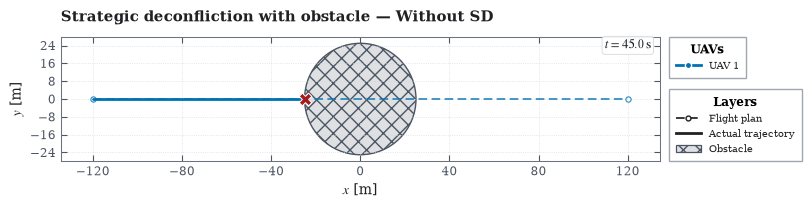

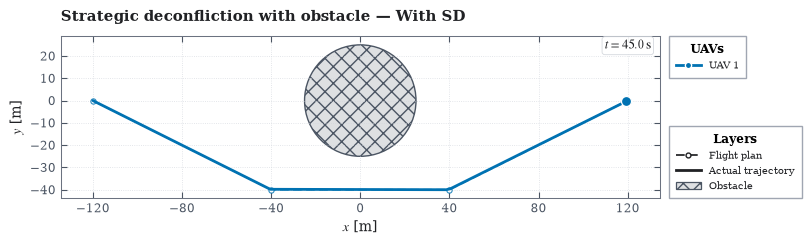

Figures: /Users/caiobianchi/Desktop/ITA/TG/TG_codigo/experiments/figs/figs_2


In [11]:
def visualization_config(case_name):
    return VisualizationConfig(
        uav_names=("UAV 1",),
        view="xy",
        show_real_trajectories=True,
        show_current_positions=True,
        show_tracks=False,
        show_flight_plans=True,
        show_sensor_reports=False,
        show_geofences=False,
        show_wind_zones=False,
        show_obstacles=True,
        frame_step=0.25,
        title=f"Strategic deconfliction with obstacle — {case_name}",
        spatial_unit="m",
    )

animation_paths = {}
for case_name, dataset_path in dataset_paths.items():
    file_label = case_name.lower().replace(" ", "_")
    figure_path = FIGURE_DIRECTORY / f"{file_label}.png"
    animation_path = FIGURE_DIRECTORY / f"{file_label}.gif"
    config = visualization_config(case_name)
    figure = plot_dataset(
        dataset_path=dataset_path,
        config=config,
        timestamp=SIMULATION_END,
        output_path=figure_path,
    )
    display(figure)
    animate_dataset(
        dataset_path=dataset_path,
        config=config,
        output_path=animation_path,
        fps=10.0,
    )
    animation_paths[case_name] = animation_path

print("Figures:", FIGURE_DIRECTORY.resolve())

### Without SD

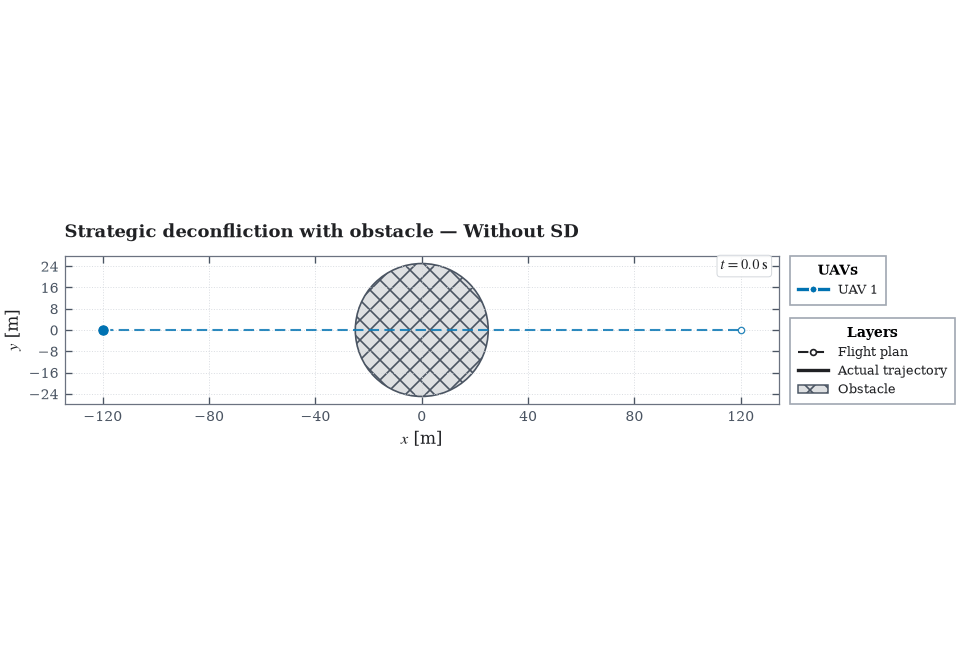

### With SD

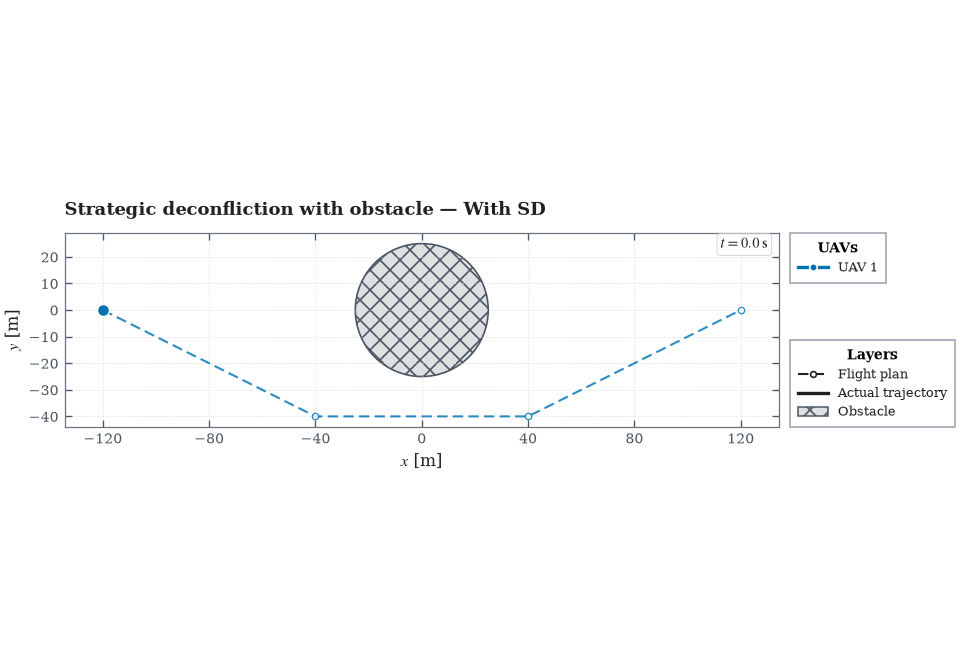

In [12]:
for case_name, animation_path in animation_paths.items():
    display(Markdown(f"### {case_name}"))
    display(Image(filename=animation_path))